# Sesgo, varianza y sobreajuste

El objetivo de un modelo predictivo no es ajustar bien los datos con que se entrenó, sino predecir bien datos nuevos. La diferencia entre las dos cosas es el centro de este capítulo {cite}`james2021,hastie2009`.

## La descomposición del error

Para un punto $x_0$, el error cuadrático esperado de la predicción de un modelo entrenado con distintas muestras se descompone en tres términos:

$$E\left[(y_0 - \hat f(x_0))^2\right] = \underbrace{\left[E\hat f(x_0) - f(x_0)\right]^2}_{\text{sesgo}^2} + \underbrace{\mathrm{Var}\left[\hat f(x_0)\right]}_{\text{varianza}} + \underbrace{\mathrm{Var}(\varepsilon)}_{\text{error irreducible}}.$$

El sesgo es el error que se introduce al aproximar un fenómeno real con un modelo simplificado: un modelo con sesgo alto hace muchos supuestos sobre la forma de la función y no captura la estructura de los datos (subajuste). La varianza es cuánto cambiaría el modelo si se entrenara con otra muestra: un modelo con varianza alta es muy sensible a las particularidades de los datos de entrenamiento y aprende también su ruido (sobreajuste). Los modelos flexibles tienen poco sesgo y mucha varianza; los rígidos, al revés. La complejidad óptima es la que minimiza la suma.

La celda siguiente lo muestra con un ejemplo clásico: se ajustan polinomios de grado creciente a datos que siguen una curva suave, y se repite el ajuste con 50 muestras distintas para ver el sesgo y la varianza directamente.

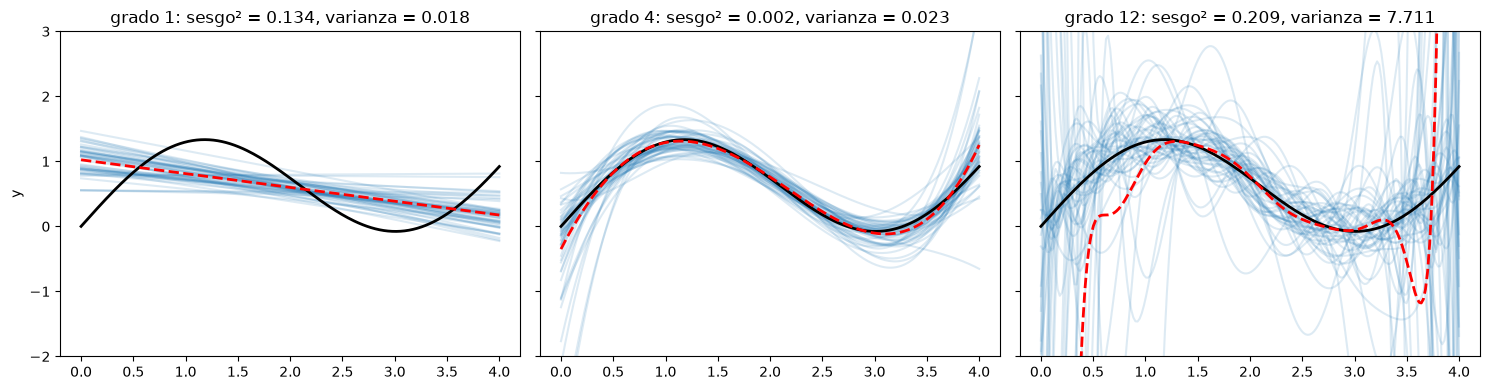

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(0)

f = lambda x: np.sin(1.5 * x) + 0.3 * x            # relación verdadera
xx = np.linspace(0, 4, 200)
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
interior = (xx > 0.4) & (xx < 3.6)          # se evalúa lejos de los bordes, donde los polinomios extrapolan
for ax, grado in zip(axs, [1, 4, 12]):
    preds = []
    for _ in range(50):
        x = rng.uniform(0, 4, 25); y = f(x) + rng.normal(0, 0.35, 25)
        c = np.polynomial.polynomial.polyfit(x, y, grado)
        preds.append(np.polynomial.polynomial.polyval(xx, c))
        ax.plot(xx, preds[-1], color='tab:blue', alpha=0.15)
    preds = np.array(preds)
    ax.plot(xx, f(xx), 'k', lw=2); ax.plot(xx, preds.mean(0), 'r--', lw=2)
    sesgo2 = np.mean((preds.mean(0) - f(xx))[interior]**2); var = np.mean(preds.var(0)[interior])
    ax.set_title(f'grado {grado}: sesgo² = {sesgo2:.3f}, varianza = {var:.3f}'); ax.set_ylim(-2, 3)
axs[0].set_ylabel('y')
plt.tight_layout(); plt.show()

En negro está la función verdadera, en azul los 50 modelos y en rojo su promedio. El polinomio de grado 1 es estable pero sistemáticamente equivocado (sesgo alto); el de grado 12 sigue en promedio la curva verdadera en buena parte del dominio, pero cada ajuste oscila mucho, sobre todo cerca de los bordes, donde hay menos datos (varianza alta); el de grado 4 logra un buen equilibrio. Los valores del título se calculan en el interior del intervalo, entre 0.4 y 3.6.

## Error de entrenamiento y error de prueba

En la práctica no se conoce $f$, pero el compromiso se ve comparando el error en los datos de entrenamiento con el error en datos independientes. El error de entrenamiento siempre disminuye al aumentar la complejidad; el de prueba disminuye al principio y luego aumenta cuando el modelo empieza a sobreajustar. Un modelo subajustado tiene errores altos en ambos conjuntos; uno sobreajustado tiene error bajo en entrenamiento y alto en prueba.

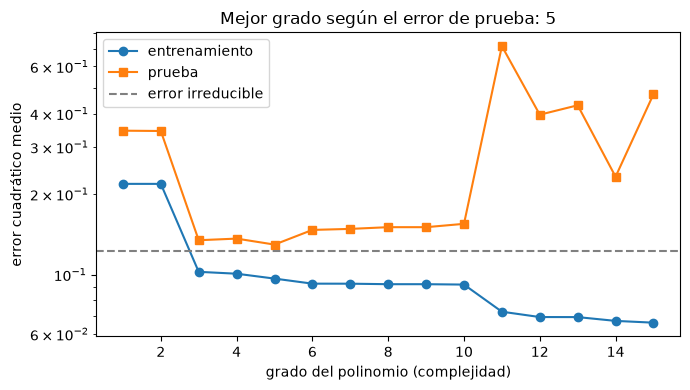

In [2]:
x_tr = rng.uniform(0, 4, 40); y_tr = f(x_tr) + rng.normal(0, 0.35, 40)
x_te = rng.uniform(0, 4, 1000); y_te = f(x_te) + rng.normal(0, 0.35, 1000)
grados = range(1, 16)
e_tr, e_te = [], []
for g in grados:
    c = np.polynomial.polynomial.polyfit(x_tr, y_tr, g)
    e_tr.append(np.mean((np.polynomial.polynomial.polyval(x_tr, c) - y_tr)**2))
    e_te.append(np.mean((np.polynomial.polynomial.polyval(x_te, c) - y_te)**2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grados, e_tr, 'o-', label='entrenamiento'); ax.plot(grados, e_te, 's-', label='prueba')
ax.axhline(0.35**2, color='0.5', ls='--', label='error irreducible')
ax.set_yscale('log'); ax.set_xlabel('grado del polinomio (complejidad)'); ax.set_ylabel('error cuadrático medio')
ax.legend(); ax.set_title(f'Mejor grado según el error de prueba: {list(grados)[int(np.argmin(e_te))]}')
plt.tight_layout(); plt.show()

## Curvas de aprendizaje

Una curva de aprendizaje muestra el error de entrenamiento y de validación en función del número de datos de entrenamiento. Es una herramienta de diagnóstico: si las dos curvas convergen a un error alto, el modelo tiene sesgo alto y más datos no ayudarán; hay que usar un modelo más flexible o mejores variables. Si hay una brecha grande entre ellas, el modelo tiene varianza alta y más datos (o regularización) sí ayudarán. Hay un matiz importante: más datos solo reducen la varianza si son representativos; si los datos de prueba contienen situaciones que no aparecen en el entrenamiento, por ejemplo una litología no muestreada, ningún volumen de datos del mismo tipo lo resolverá.

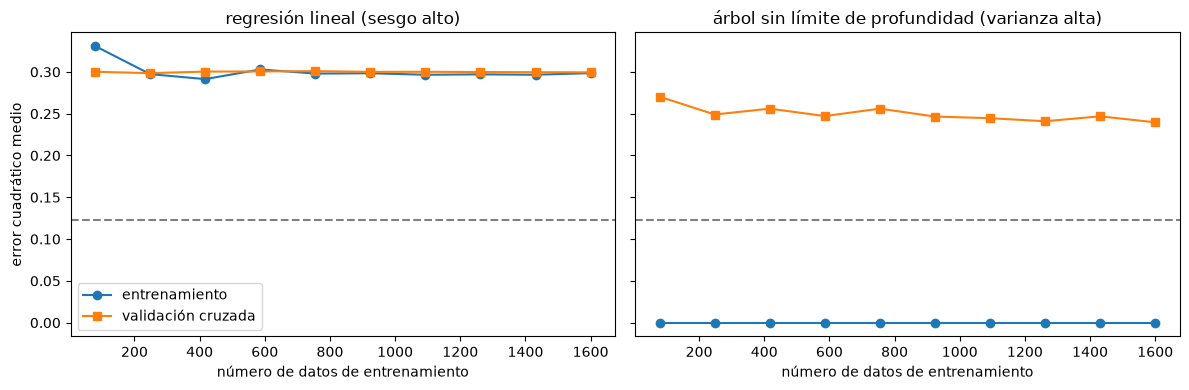

In [3]:
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

X = rng.uniform(0, 4, (2000, 1)); y = f(X[:, 0]) + rng.normal(0, 0.35, 2000)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nom, mod) in zip(axs, [('regresión lineal (sesgo alto)', LinearRegression()),
                                ('árbol sin límite de profundidad (varianza alta)', DecisionTreeRegressor(random_state=0))]):
    tam, tr, va = learning_curve(mod, X, y, train_sizes=np.linspace(0.05, 1, 10), cv=5, scoring='neg_mean_squared_error')
    ax.plot(tam, -tr.mean(1), 'o-', label='entrenamiento'); ax.plot(tam, -va.mean(1), 's-', label='validación cruzada')
    ax.axhline(0.35**2, color='0.5', ls='--'); ax.set_title(nom); ax.set_xlabel('número de datos de entrenamiento')
axs[0].set_ylabel('error cuadrático medio'); axs[0].legend()
plt.tight_layout(); plt.show()

## Cómo reducir el sesgo y la varianza

Para reducir el sesgo se usan modelos más flexibles, se agregan variables o interacciones informativas, o se reduce la regularización. Para reducir la varianza se consiguen más datos representativos, se quitan variables irrelevantes, se regulariza (penalizando la magnitud de los coeficientes, capítulo {doc}`12_RegresionLineal`), se limita la complejidad (profundidad máxima de un árbol, número mínimo de datos por hoja), se detiene el entrenamiento a tiempo (parada temprana en redes neuronales y boosting) o se promedian muchos modelos (bagging y bosques aleatorios, capítulo {doc}`15_Arboles_Ensambles`). El boosting, al contrario, combina modelos simples de sesgo alto para reducir el sesgo del conjunto.

La celda siguiente muestra el efecto de la profundidad máxima de un árbol de clasificación sobre un inventario sintético de deslizamientos, un caso típico de control de la complejidad.

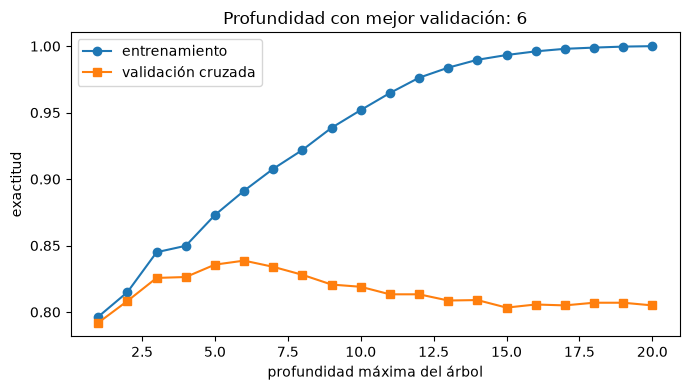

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

n = 3000
pend = rng.gamma(4, 6, n); lluv = rng.normal(2500, 500, n); dist = rng.exponential(250, n)
eta = -6 + 0.12 * pend + 0.0012 * lluv - 0.004 * dist + 0.002 * pend * (lluv - 2500) / 10
yb = (rng.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
Xb = np.column_stack([pend, lluv, dist])
prof = range(1, 21)
res = [cross_validate(DecisionTreeClassifier(max_depth=d, random_state=0), Xb, yb, cv=5, return_train_score=True) for d in prof]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prof, [r['train_score'].mean() for r in res], 'o-', label='entrenamiento')
ax.plot(prof, [r['test_score'].mean() for r in res], 's-', label='validación cruzada')
ax.set_xlabel('profundidad máxima del árbol'); ax.set_ylabel('exactitud'); ax.legend()
mejor = list(prof)[int(np.argmax([r['test_score'].mean() for r in res]))]
ax.set_title(f'Profundidad con mejor validación: {mejor}'); plt.tight_layout(); plt.show()

## Para profundizar

La sección 2.2 de {cite}`james2021` y el capítulo 7 de {cite}`hastie2009` desarrollan la descomposición sesgo-varianza. El notebook 11 del curso muestra el compromiso con distintos modelos de `scikit-learn`.